Epoch 5/20, Loss: 0.00953
Epoch 10/20, Loss: 0.00221
Epoch 15/20, Loss: 0.00130
Epoch 20/20, Loss: 0.00338
Epoch 5/20, Loss: 0.00905
Epoch 10/20, Loss: 0.00287
Epoch 15/20, Loss: 0.00322
Epoch 20/20, Loss: 0.00385

BiRNN MSE: 2649.353
FFNN MSE: 2938.561


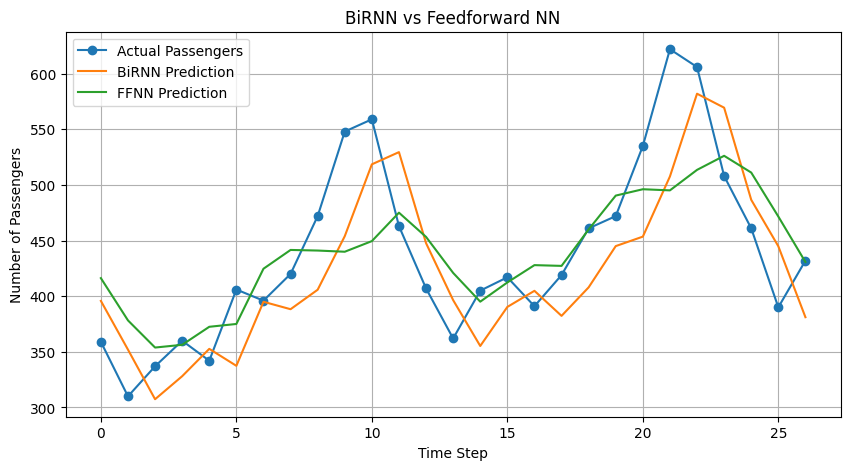

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)
data = df.iloc[:, 1].values.astype("float32").reshape(-1, 1)

scaler = MinMaxScaler()
scaled = scaler.fit_transform(data)

SEQ_LENGTH = 10
X = np.array([scaled[i:i+SEQ_LENGTH] for i in range(len(scaled)-SEQ_LENGTH)])
y = np.array([scaled[i+SEQ_LENGTH] for i in range(len(scaled)-SEQ_LENGTH)])

split = int(len(X) * 0.8)
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

loader = DataLoader(TensorDataset(X_train, y_train), batch_size=16, shuffle=True)

class BiRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(1, 16, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class FeedforwardNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(SEQ_LENGTH, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.fc2(self.relu(self.fc1(x)))

def train_model(model):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(20):
        model.train()
        for inputs, targets in loader:
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

        if (epoch + 1) % 5 == 0:
            print(f"Epoch {epoch+1}/20, Loss: {loss.item():.5f}")

    return model

birnn = train_model(BiRNN())
ffnn = train_model(FeedforwardNN())

birnn.eval()
ffnn.eval()

with torch.no_grad():
    pred_birnn = birnn(X_test).numpy()
    pred_ffnn = ffnn(X_test).numpy()

actual = scaler.inverse_transform(y_test.numpy())
pred_birnn = scaler.inverse_transform(pred_birnn)
pred_ffnn = scaler.inverse_transform(pred_ffnn)

mse_birnn = mean_squared_error(actual, pred_birnn)
mse_ffnn = mean_squared_error(actual, pred_ffnn)

print("\nBiRNN MSE:", round(mse_birnn, 3))
print("FFNN MSE:", round(mse_ffnn, 3))

plt.figure(figsize=(10, 5))
plt.plot(actual, label="Actual Passengers", marker="o")
plt.plot(pred_birnn, label="BiRNN Prediction")
plt.plot(pred_ffnn, label="FFNN Prediction")
plt.title("BiRNN vs Feedforward NN")
plt.xlabel("Time Step")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.show()
